# Emotional, neutral and mechanical prompts: same node, same day

**Question:** emotional prompts (**E**) produce more CPU throttling than neutral prompts (**N**). Do mechanical prompts (**M**) behave like emotional ones, or like neutral ones?

- If **M is like E**, the E−N difference is probably about the *kind of task*, not the *emotional content*.
- If **M is like N**, the difference is specific to emotional prompts.

**Data:** only node/dates that have **E, N and M** runs, so all three comparisons use exactly the same machines and days.

**Measures** (PTE = processor throttle events, from `core_power.throttle`):
- **PTE mean rate** — throttle events per second.
- **PTE / cycles** — throttle events per CPU cycle.

**Three comparisons**, each analysed exactly like `fulltrace_analysis_matched.ipynb`:
- **E vs N** — the main effect, on these node/dates.
- **M vs N** — does mechanical also differ from neutral?
- **E vs M** — the direct test. E vs M ≈ 0 means M behaves like E.

Positive numbers mean the first condition is higher. Inputs are read-only; all outputs go to `OUT`.

**Steps**
1. Find the node/dates that have all three conditions.
2. Compare every run of one condition with every run of the other.
3. Estimate each overall difference and its uncertainty.
4. Check whether a single date or node drives the result.
5. Conclusion: is M like E, like N, or can't we tell? (Method details are in the appendix at the end.)

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
from fulltrace_node_day import load_recordings
from fulltrace_matched import prepare, analyze, block_summary, SPECS as ALL_SPECS

SELECTED_FEATURES = {"core_power.throttle__mean_rate",
                     "core_power.throttle__per_cycle"}
RENAME = {"core_power.throttle__mean_rate": "PTE mean rate"}
SPECS = [(feature, RENAME.get(feature, label), scale, unit)
         for feature, label, scale, unit in ALL_SPECS if feature in SELECTED_FEATURES]

CONDITIONS = ("emotional", "neutral", "mechanical")
COMPARISONS = [("emotional", "neutral", "E vs N"),
               ("mechanical", "neutral", "M vs N"),
               ("emotional", "mechanical", "E vs M")]
TIMEZONE = "America/Chicago"
TEST_BOOTSTRAPS = 19999
INTERVAL_BOOTSTRAPS = 1999
SEED = 42
WORKERS = 4  # Use 1 for a single process.
OUT = ROOT / "results/fulltrace_matched_ENM_2026-10-26_two_features"
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {"emotional": "#C44E52", "neutral": "#4477AA", "mechanical": "#55A868"}
COMPARISON_COLORS = {"E vs N": "#C44E52", "M vs N": "#55A868", "E vs M": "#333333"}
FEATURES = [s[0] for s in SPECS]
LABELS = {s[0]: s[1] for s in SPECS}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Find node/dates with all three conditions

Same inclusion rules as the main notebook: successful 70B runs with recomputed feature files, dated by start time in Chicago time. We keep only node/dates with at least one **E, N and M** run.

The run-order table matters for interpretation: it shows **when** each condition ran on each date.

In [2]:
all_traces, _, _, _ = load_recordings(ROOT, TIMEZONE, conditions=CONDITIONS)
present = all_traces.groupby(["node", "day"]).condition.agg(set)
keys = present[present.apply(lambda s: set(CONDITIONS) <= s)].index
traces = all_traces.set_index(["node", "day"]).loc[keys].reset_index()
traces = traces.loc[:, [c for c in traces if "__" not in c or c in FEATURES]]
KEEP = {f"{day} / {node}" for node, day in keys}

print(f"{len(traces)} runs on {len(keys)} node/dates, {traces.node.nunique()} nodes, "
      f"{traces.day.nunique()} dates, batches: {', '.join(sorted(traces.batch.unique()))}")
display(pd.crosstab([traces.day, traces.node], traces.condition))
order = traces.sort_values("started_local")[["day", "node", "condition", "run_label", "started_local"]]
order["start_time"] = order.pop("started_local").str[11:16]
display(order.pivot_table(index=["day", "node"], columns="condition", values="start_time",
                          aggfunc=", ".join))

contrasts, blocks, sources = {}, {}, []
for first, second, name in COMPARISONS:
    _, b, c, s, _, _ = prepare(ROOT, TIMEZONE, features=FEATURES, first=first, second=second)
    c["label"] = c.feature.map(LABELS)
    blocks[name] = b.loc[b.block.isin(KEEP)].reset_index(drop=True)
    contrasts[name] = c.loc[c.block.isin(KEEP)].reset_index(drop=True)
    sources.append(s)
sources = pd.concat(sources).drop_duplicates()
sources = sources.loc[sources.path.isin(set(traces.feature_file) | set(traces.metadata_file))]
block_contrasts = pd.concat([block_summary(c).assign(comparison=name) for name, c in contrasts.items()])

traces.to_csv(OUT / "input_recordings.csv", index=False)
sources.to_csv(OUT / "input_checksums.csv", index=False)
pd.concat([c.assign(comparison=name) for name, c in contrasts.items()]).to_csv(
    OUT / "matched_contrasts.csv", index=False)
block_contrasts.to_csv(OUT / "block_summaries.csv", index=False)
display(pd.DataFrame({name: [len(b), int((b.n_E * b.n_N).sum())] for name, b in blocks.items()},
                     index=["node/dates", "cross pairs per measure"]))

44 runs on 10 node/dates, 10 nodes, 2 dates, batches: batch_004_enm, batch_005_nem


condition        emotional  mechanical  neutral
day        node                                
2026-10-12 184           1           1        1
           230           1           1        1
           231           1           1        1
           232           1           1        1
           239           1           1        1
2026-10-25 183           2           2        2
           187           2           2        1
           218           2           2        2
           220           2           2        2
           222           2           2        2

condition           emotional    mechanical       neutral
day        node                                          
2026-10-12 184          14:48         11:59         11:22
           230          14:48         11:24         12:00
           231          14:48         11:24         12:00
           232          14:48         12:00         11:22
           239          14:48         11:24         12:00
2026-10-25 183   14:41, 21:25  12:59, 15:38  13:53, 18:31
           187   13:55, 18:31  14:41, 21:25         15:29
           218   12:59, 15:38  13:54, 18:31  14:41, 21:25
           220   13:55, 18:31  14:41, 21:25  12:58, 15:26
           222   12:59, 15:38  13:54, 18:31  14:41, 21:25

,E vs N,M vs N,E vs M
node/dates,10,10,10
cross pairs per measure,23,23,25


## 2. Compare every run with every run

Within each node/date, every run of the first condition is compared with every run of the second. With 2 runs each, that gives four differences:

> difference = first run / second run − 1, shown as a percentage

These differences reuse the same runs, so they aren't independent. The model in section 3 accounts for this, exactly as in the main notebook.

**Figure:** one row per node/date, one panel per comparison. Small dots are the individual cross pairs; the black diamond is the node/date's average. Red = first condition higher, blue = second higher.

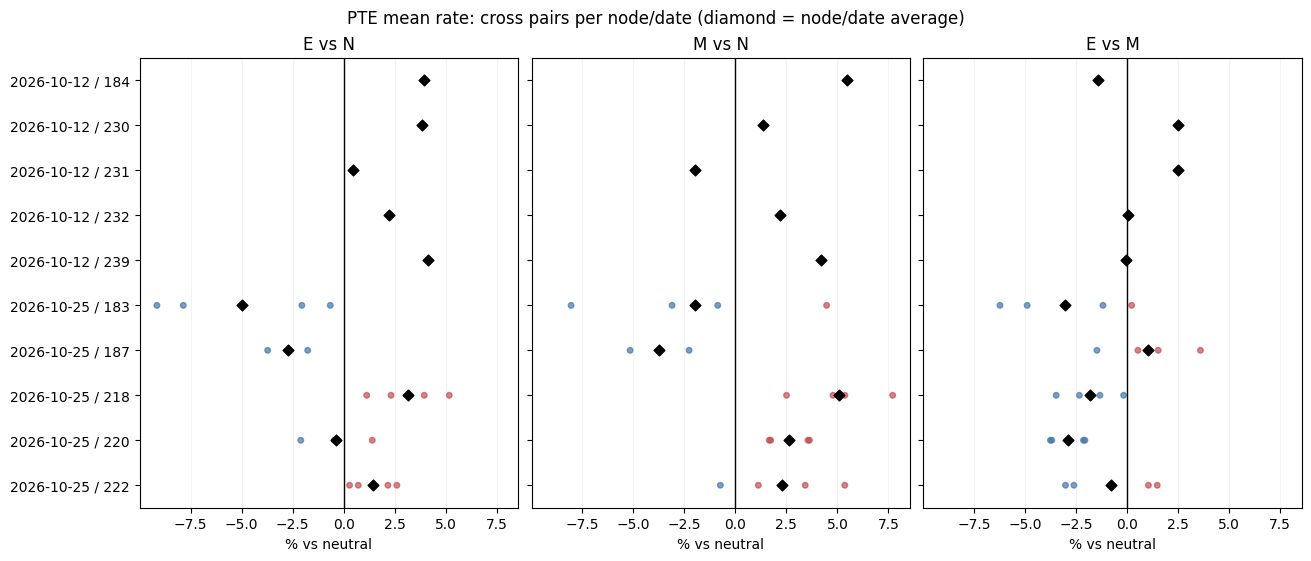

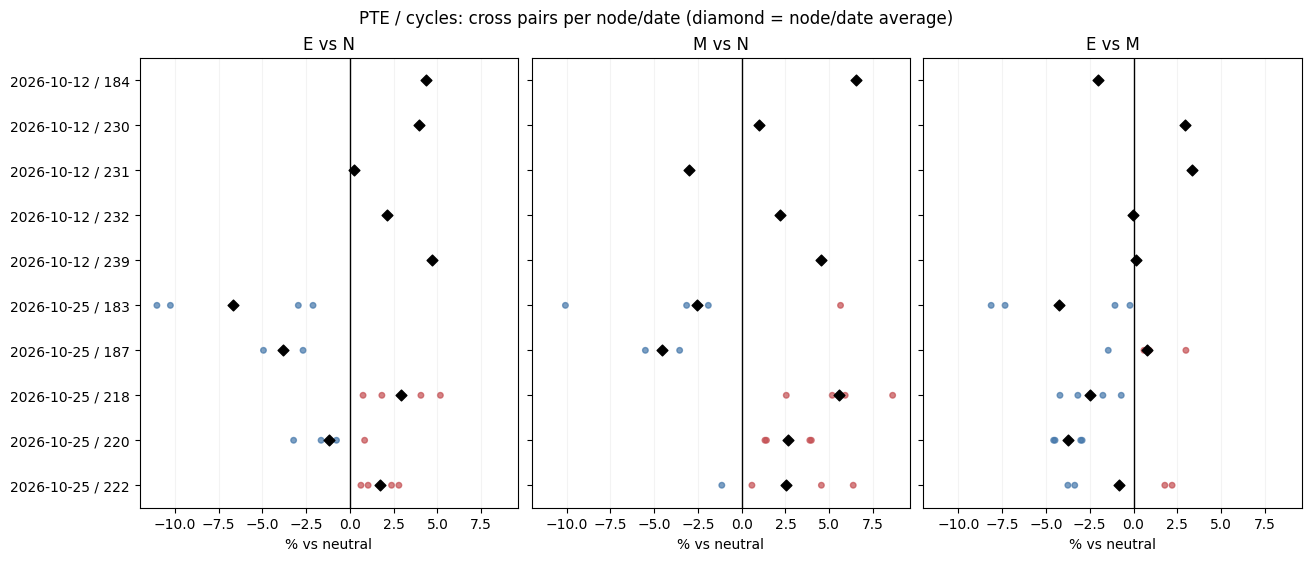

In [3]:
order = sorted(KEEP)
for feature, label, scale, unit in SPECS:
    fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(13, 5.5), sharey=True, sharex=True,
                             layout="constrained")
    for ax, (first, second, name) in zip(axes, COMPARISONS):
        sub = contrasts[name].loc[contrasts[name].feature == feature]
        means = block_contrasts.loc[(block_contrasts.comparison == name)
                                    & (block_contrasts.feature == feature)].set_index("block")
        for i, block in enumerate(order):
            pairs = sub.loc[sub.block == block, "effect"]
            ax.scatter(pairs, np.full(len(pairs), i), s=16, alpha=.7,
                       color=["#C44E52" if v > 0 else "#4477AA" for v in pairs])
            ax.scatter(means.loc[block, "effect"], i, marker="D", s=30, color="black", zorder=3)
        ax.axvline(0, color="black", linewidth=1)
        ax.set(title=name, xlabel=unit, yticks=range(len(order)), yticklabels=order,
               ylim=(len(order) - .5, -.5))
        ax.grid(axis="x", alpha=.15)
    fig.suptitle(f"{label}: cross pairs per node/date (diamond = node/date average)")
    save_figure(fig, f"matched_differences_{feature.rsplit('__', 1)[1]}")

## 3. The overall differences and their uncertainty

Each comparison is analysed with the main notebook's model:

> difference = overall effect + node + date + node/date + run noise

- **Pairs sharing a run are linked**, so reused runs aren't over-counted.
- **95% CI** — how precisely we know the *average* difference.
- **New-group range** — where one comparison on a *new* node and *new* date would likely fall.
- **p-value** — is the average difference zero? Bonferroni-corrected for the two measures (p × 2), separately for each comparison.

**Reading "not significant":** a non-significant E vs M does **not** prove that M and E are the same. With few node/dates, a real difference can go undetected. The CI shows which differences are still plausible.

The main notebook's E vs N result on **all** node/dates is shown as a grey reference.

In [4]:
estimates, sensitivity = [], []
for first, second, name in COMPARISONS:
    print(name)
    est, sens, _, _ = analyze(contrasts[name], test_repeats=TEST_BOOTSTRAPS,
                              interval_repeats=INTERVAL_BOOTSTRAPS, seed=SEED, workers=WORKERS)
    estimates.append(est.assign(comparison=name))
    sensitivity.append(sens.assign(comparison=name))
estimates, sensitivity = pd.concat(estimates, ignore_index=True), pd.concat(sensitivity, ignore_index=True)
estimates["label"] = estimates.feature.map(LABELS)
sensitivity["label"] = sensitivity.feature.map(LABELS)
estimates.to_csv(OUT / "overall_effects.csv", index=False)
sensitivity.to_csv(OUT / "leave_one_group_out.csv", index=False)
configuration = dict(timezone=TIMEZONE, date_rule="trace start date", seed=SEED,
                     test_bootstraps=TEST_BOOTSTRAPS, interval_bootstraps=INTERVAL_BOOTSTRAPS,
                     workers=WORKERS, features=FEATURES, comparisons=[c[2] for c in COMPARISONS],
                     n_traces=len(traces), n_groups=len(KEEP),
                     pairing="every run vs every run within node/date; shared-run covariance",
                     correction="Bonferroni over two measures, within each comparison")
(OUT / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")

report = pd.DataFrame({"Comparison": estimates.comparison, "Feature": estimates.label,
    "Average (%)": estimates.display_estimate,
    "95% CI lower": estimates.display_ci_low, "95% CI upper": estimates.display_ci_high,
    "New-group range lower": estimates.display_prediction_low,
    "New-group range upper": estimates.display_prediction_high,
    "Bonferroni p": estimates.p_bonferroni,
    "First higher (node/dates)": [f"{p}/{n}" for p, n in zip(estimates.n_positive, estimates.n_blocks)],
    "First higher (cross pairs)": [f"{p}/{n}" for p, n in zip(estimates.n_pairs_positive, estimates.n_pairs)],
    "MC-sensitive": estimates.mc_sensitive})
display(report.round(4))
report.to_csv(OUT / "readable_summary.csv", index=False)

reference = pd.read_csv(ROOT / "results/fulltrace_matched_EN_2026-10-24_two_features/overall_effects.csv")
reference = reference.set_index("feature")
display(Markdown("**Main notebook E vs N (all node/dates):** " + "; ".join(
    f"{LABELS[f]} {reference.loc[f, 'display_estimate']:+.2f}% "
    f"(95% CI {reference.loc[f, 'display_ci_low']:+.2f} to {reference.loc[f, 'display_ci_high']:+.2f})"
    for f in FEATURES)))

E vs N


Completed 1/2: PTE mean rate


Completed 2/2: PTE / cycles


M vs N


Completed 1/2: PTE mean rate


...

E vs M


Completed 1/2: PTE mean rate


Completed 2/2: PTE / cycles


,Comparison,Feature,Average (%),95% CI lower,95% CI upper,New-group range lower,New-group range upper,Bonferroni p,First higher (node/dates),First higher (cross pairs),MC-sensitive
0,E vs N,PTE mean rate,0.9028,-2.5791,4.3895,-6.1912,8.5025,1.0000,7/10,14/23,False
1,E vs N,PTE / cycles,0.5935,-3.9466,5.2268,-7.8702,9.9535,1.0000,7/10,14/23,False
2,M vs N,PTE mean rate,1.5092,-0.4947,3.5187,-5.7500,9.2811,0.2439,7/10,16/23,False
3,M vs N,PTE / cycles,1.4440,-0.9808,4.0604,-6.9749,10.8933,0.4001,7/10,16/23,False
4,E vs M,PTE mean rate,-0.7062,-2.3834,0.9901,-5.6002,4.4150,1.0000,4/10,9/25,False
5,E vs M,PTE / cycles,-0.9644,-3.4203,1.7071,-7.1200,5.7179,1.0000,4/10,8/25,False


**Main notebook E vs N (all node/dates):** PTE mean rate +2.64% (95% CI +0.34 to +4.96); PTE / cycles +2.66% (95% CI -0.05 to +5.30)

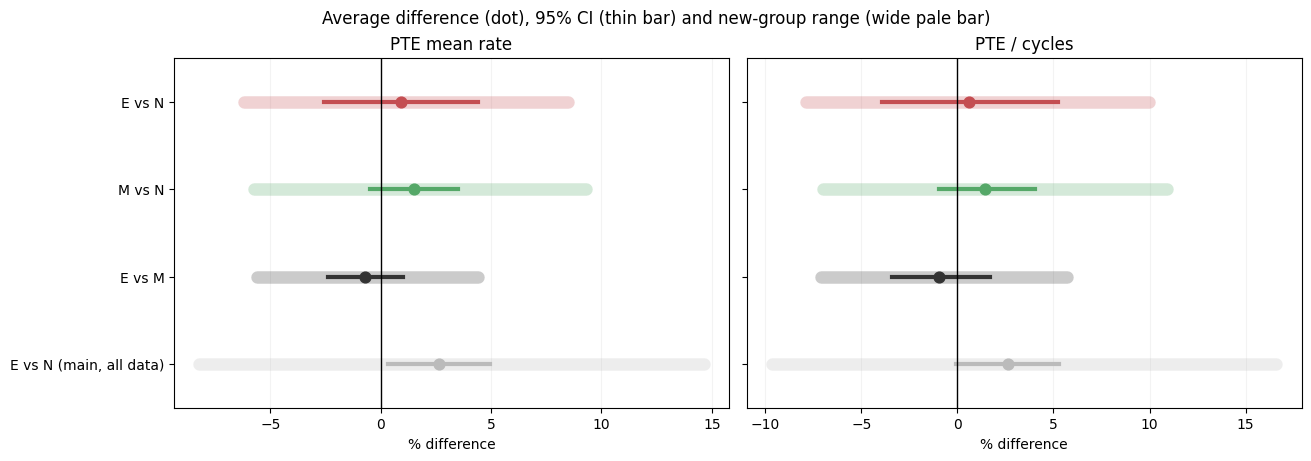

In [5]:
rows = [c[2] for c in COMPARISONS] + ["E vs N (main, all data)"]
fig, axes = plt.subplots(1, len(SPECS), figsize=(13, 4.5), sharey=True, layout="constrained")
for ax, feature in zip(axes, FEATURES):
    sub = estimates.loc[estimates.feature == feature].set_index("comparison")
    ref = reference.loc[feature]
    for i, name in enumerate(rows):
        r = sub.loc[name] if name in sub.index else ref
        color = COMPARISON_COLORS.get(name, "#BBBBBB")
        ax.plot([r.display_prediction_low, r.display_prediction_high], [i, i], color=color,
                alpha=.25, linewidth=9, solid_capstyle="round")
        ax.plot([r.display_ci_low, r.display_ci_high], [i, i], color=color, linewidth=3)
        ax.scatter(r.display_estimate, i, color=color, s=60, zorder=3)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=LABELS[feature], xlabel="% difference", yticks=range(len(rows)), yticklabels=rows,
           ylim=(len(rows) - .5, -.5))
    ax.grid(axis="x", alpha=.15)
fig.suptitle("Average difference (dot), 95% CI (thin bar) and new-group range (wide pale bar)")
save_figure(fig, "overall_effects")

## 4. Does one date or node drive the result?

Each comparison is refitted with **one whole date** or **one whole node** left out. Look for estimates that keep the same sign and roughly the same size.

With only two dates, leaving one out means fitting a single date. Treat the drop-one-date rows as a rough check.

In [6]:
sensitivity_summary = sensitivity.groupby(["comparison", "label", "omitted_type"], sort=False).agg(
    refits=("same_sign", "size"), same_direction=("same_sign", "sum"),
    smallest_estimate=("display_estimate", "min"), largest_estimate=("display_estimate", "max"))
display(sensitivity_summary.round(2))
sensitivity_summary.to_csv(OUT / "sensitivity_summary.csv")

refits  same_direction  \
comparison label         omitted_type                           
E vs N     PTE mean rate day                2               1   
                         node              10              10   
           PTE / cycles  day                2               1   
                         node              10              10   
M vs N     PTE mean rate day                2               2   
                         node              10              10   
           PTE / cycles  day                2               2   
                         node              10              10   
E vs M     PTE mean rate day                2               1   
                         node              10              10   
           PTE / cycles  day                2               1   
                         node              10              10   

                                       smallest_estimate  largest_estimate  
comparison label         omitted_type                                       
E vs N     PTE mean rate day                       -0.66              2.92  
                         node                       0.50              1.66  
           PTE / cycles  day                       -1.38              3.05  
                         node                       0.13              1.50  
M vs N     PTE mean rate day                        1.10              2.22  
                         node                       0.94              2.06  
           PTE / cycles  day                        1.05              2.19  
                         node                       0.80              2.08  
E vs M     PTE mean rate day                       -1.53              0.69  
                         node                      -1.03             -0.43  
           PTE / cycles  day                       -2.12              0.85  
                         node                      -1.45             -0.56

## 5. Conclusion: is M like E or like N?

For each measure, we compare two ranges:

- the **E vs M** 95% CI, and
- **zero** and the **E vs N** estimate on these node/dates.

| E vs M CI includes 0? | E vs M CI includes the E−N estimate? | Reading |
|---|---|---|
| yes | no | **M looks like E** |
| no | yes | **M looks like N** (different from E) |
| yes | yes | **Can't tell yet** — the data fit both |
| no | no | **M is in between** |

**Limits:**
- Few node/dates (two dates). Each node appears on only one date, so node and node/date effects can't be separated.
- **Run timing:** on 2026-10-12, N and M runs were interleaved in the morning while all E runs ran together in the afternoon (see the run-order table). On 2026-10-25 the conditions were interleaved through the day.
- The two measures were chosen after looking at the data; treat results as exploratory.

In [7]:
for feature in FEATURES:
    sub = estimates.loc[estimates.feature == feature].set_index("comparison")
    en, mn, em = sub.loc["E vs N"], sub.loc["M vs N"], sub.loc["E vs M"]
    has_zero = em.display_ci_low <= 0 <= em.display_ci_high
    has_en = em.display_ci_low <= en.display_estimate <= em.display_ci_high
    reading = {(True, False): "M looks like E", (False, True): "M looks like N (different from E)",
               (True, True): "can't tell yet: the data fit both", (False, False): "M is in between"}
    display(Markdown(
        f"**{LABELS[feature]}:** E vs N = **{en.display_estimate:+.2f}%** (p = {en.p_bonferroni:.3g}); "
        f"M vs N = **{mn.display_estimate:+.2f}%** (p = {mn.p_bonferroni:.3g}); "
        f"E vs M = **{em.display_estimate:+.2f}%** "
        f"(95% CI {em.display_ci_low:+.2f} to {em.display_ci_high:+.2f}; p = {em.p_bonferroni:.3g}). "
        f"**Reading: {reading[(has_zero, has_en)]}.**"))

for source in sources.itertuples(index=False):
    assert hashlib.sha256((ROOT / source.path).read_bytes()).hexdigest() == source.sha256
print("Verified: input metadata and feature files are unchanged.")
print(f"Tables, figures, and configuration: {OUT.relative_to(ROOT)}")

**PTE mean rate:** E vs N = **+0.90%** (p = 1); M vs N = **+1.51%** (p = 0.244); E vs M = **-0.71%** (95% CI -2.38 to +0.99; p = 1). **Reading: can't tell yet: the data fit both.**

**PTE / cycles:** E vs N = **+0.59%** (p = 1); M vs N = **+1.44%** (p = 0.4); E vs M = **-0.96%** (95% CI -3.42 to +1.71; p = 1). **Reading: can't tell yet: the data fit both.**

Verified: input metadata and feature files are unchanged.
Tables, figures, and configuration: results/fulltrace_matched_ENM_2026-10-26_two_features


## Appendix: method details

- **Data points:** log(first run / second run) for every run of one condition against every run of the other, within a node/date. PTE / cycles is computed per run first.
- **Model** (`analysis/lib/fulltrace_matched.py`, same as the main notebook): difference = overall effect + node + date + node/date + run noise. Node, date and node/date terms are random intercepts, fitted by Gaussian maximum likelihood. Pairs sharing a run are correlated through its run noise. Redundant pairs (e.g. the fourth pair in a 2+2 node/date) add no information and are left out of the likelihood, but appear in plots and counts.
- **Test:** parametric-bootstrap likelihood-ratio test of overall effect = 0. Bonferroni correction (p × 2) covers the two measures within each comparison.
- **95% CI:** studentized parametric bootstrap, pointwise.
- **Each comparison is fitted separately**, so E vs N, M vs N and E vs M estimates need not add up exactly.